<a href="https://colab.research.google.com/github/azaanmumtaz01-boop/handwritten-digit-recognition/blob/main/Copy_of_health_risk_prediction_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#health risk prediction system
## major project


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:

!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
heart_disease = fetch_ucirepo(id=45)
x = heart_disease.data.features
y = heart_disease.data.targets
print(x.head())
print(y.head())

   age  sex  cp  trestbps  chol  fbs  ...  thalach  exang  oldpeak  slope   ca  thal
0   63    1   1       145   233    1  ...      150      0      2.3      3  0.0   6.0
1   67    1   4       160   286    0  ...      108      1      1.5      2  3.0   3.0
2   67    1   4       120   229    0  ...      129      1      2.6      2  2.0   7.0
3   37    1   3       130   250    0  ...      187      0      3.5      3  0.0   3.0
4   41    0   2       130   204    0  ...      172      0      1.4      1  0.0   3.0

[5 rows x 13 columns]
   num
0    0
1    2
2    1
3    0
4    0


In [ ]:
print("Number of rows:",x.shape[0])
print("Number of features:",x.shape[1])
print("\nfeature names:")
print(x.columns)

Number of rows: 303
Number of features: 13

feature names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')


In [ ]:
print("Missing values:")
print(x.isnull().sum())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


In [ ]:
x = x.replace("?",np.nan)
x = x.apply(pd.to_numeric,errors="coerce")
x = x.fillna(x.median())
print("Missing values after cleaning:")
print(x.isnull().sum())

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64


In [ ]:
y = y.iloc[:,0]
y = (y>0).astype(int)
print("Target values:")
print(y.value_counts())

Target values:
num
0    164
1    139
Name: count, dtype: int64


In [ ]:
X_train , X_test ,  y_train , y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (242, 13)
Testing data: (61, 13)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("data scaling completed.")

data scaling completed.


In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled , y_train)
print("Model training completed.")

Model training completed.


In [ ]:
y_pred = model.predict(X_test_scaled)
print("predictions:")
print(y_pred)

predictions:
[0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 0 1 0 1 1 0 0 1 0
 0 0 1 1 1 1 1 0 0 1 0 1 0 0 1 1 0 0 1 1 1 0 0 1]


In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:",accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.8688524590163934
Accuracy Percentage: 86.88524590163934 %


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[27  6]
 [ 2 26]]


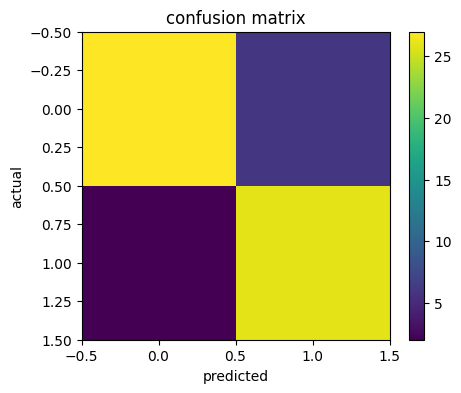

In [ ]:
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("confusion matrix")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.colorbar()
plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": x.columns,
    "Coefficient":model.coef_[0]
})
importance["Absolute_Coefficient"] = abs(
    importance["Coefficient"]
)
importance = importance.sort_values(
    by="Absolute_Coefficient", ascending=False
)
print(importance)

     Feature  Coefficient  Absolute_Coefficient
11        ca     1.107898              1.107898
12      thal     0.677821              0.677821
1        sex     0.655563              0.655563
2         cp     0.543483              0.543483
8      exang     0.383642              0.383642
10     slope     0.354072              0.354072
7    thalach    -0.348486              0.348486
3   trestbps     0.313655              0.313655
5        fbs    -0.220560              0.220560
6    restecg     0.217329              0.217329
4       chol     0.215375              0.215375
9    oldpeak     0.149953              0.149953
0        age    -0.103159              0.103159


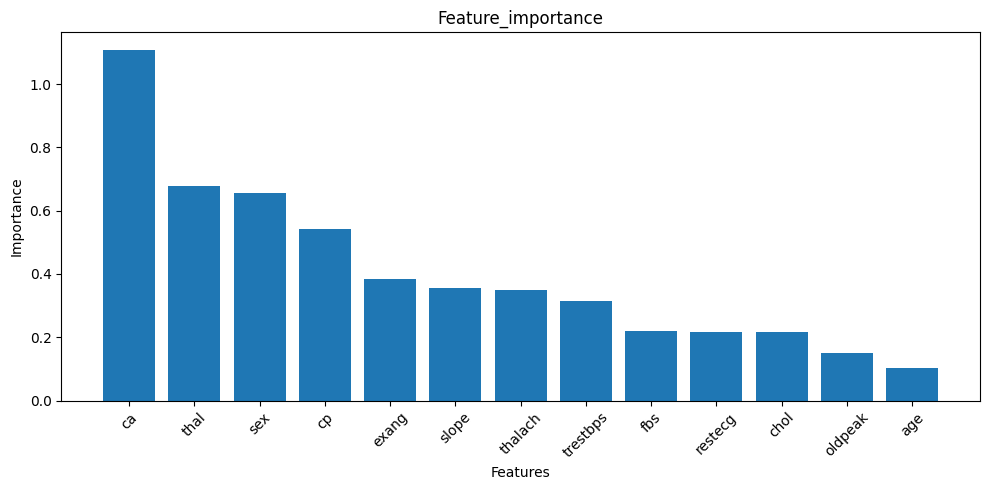

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(
    importance["Feature"],
    importance["Absolute_Coefficient"]
)
plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature_importance")
plt.tight_layout()
plt.show()